# Task 1: Fake news classifier (Fakeddit, text + metadata)

Binary classification of Reddit posts from the Fakeddit dataset into **fake (0)** and **real (1)** using the post title and three engagement features.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from pathlib import Path
from sklearn.compose import ColumnTransformer  # leidzia tekstui ir skaiciams daryti skirtingus dalykus, o paskui viska sudeda i viena vieta
from sklearn.pipeline import Pipeline, make_pipeline  # sujungia visus zingsnius i viena grandine, kad testo duomenys neistu i mokyma
from sklearn.impute import SimpleImputer  # uzpildo tuscius langelius, nes modelis su tusciais neveikia
from sklearn.preprocessing import FunctionTransformer, StandardScaler  # savos funkcijos zingsniai ir skaiciu suvienodinimas i panasu dydi
from sklearn.feature_extraction.text import TfidfVectorizer  # zodzius pavercia skaiciais: retas, bet cia pasikartojantis zodis gauna daugiau tasku
from sklearn.linear_model import LogisticRegression  # modelis: kiekvienas zodis gauna taskus uz 'tikra' ar 'netikra', sudejus gaunam tikimybe
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay  # budai patikrinti, kaip gerai modelis speja

DATA = Path("../data/multimodal_only_samples-20261006T085257Z-1-001/multimodal_only_samples")  # imam dali, kur visi irasai turi paveiksleli
FIG = Path("../report/figures"); FIG.mkdir(parents=True, exist_ok=True)  # grafikus iskart saugom ataskaitai

## 1. Load data
Only the columns we need, to keep memory low. `subreddit` is loaded for exploration only.

In [2]:
COLS = ["clean_title", "score", "num_comments", "upvote_ratio", "subreddit", "2_way_label"]  # imam tik 6 stulpelius is 16, kitaip pritruktu atminties
train_full = pd.read_csv(DATA / "multimodal_train.tsv", sep="\t", usecols=COLS)  # duomenys mokymui
test_full = pd.read_csv(DATA / "multimodal_test_public.tsv", sep="\t", usecols=COLS)  # atskiri duomenys testui, modelis ju nemato kol mokosi
train_full.shape, test_full.shape

((564000, 6), (59319, 6))

## 2. Exploration

In [3]:
print(train_full["2_way_label"].map({0: "fake", 1: "real"}).value_counts(normalize=True).round(3))  # apie 61% netikru: net spejant visada 'netikra' butum teisus 61% atveju
print()
print("Missing values:"); print(train_full.isna().sum())  # kiek tusciu langeliu kiekviename stulpelyje

2_way_label
fake    0.606
real    0.394
Name: proportion, dtype: float64

Missing values:
clean_title          0
num_comments    167857
score                0
subreddit            0
upvote_ratio    167857
2_way_label          0
dtype: int64


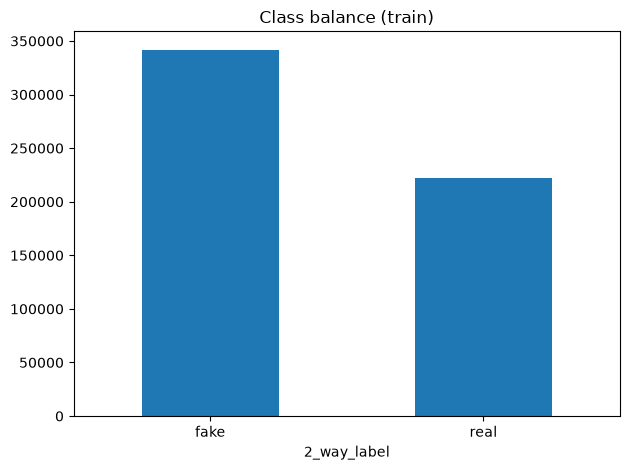

In [4]:
ax = train_full["2_way_label"].map({0: "fake", 1: "real"}).value_counts().plot.bar(rot=0, title="Class balance (train)")
plt.tight_layout(); plt.savefig(FIG / "class_balance.png", dpi=120); plt.show()

                count  mean  std  min  25%  50%   75%    max
2_way_label                                                 
0            341919.0   6.2  5.3  1.0  2.0  5.0   8.0  553.0
1            222081.0   9.5  5.6  1.0  6.0  9.0  12.0   66.0


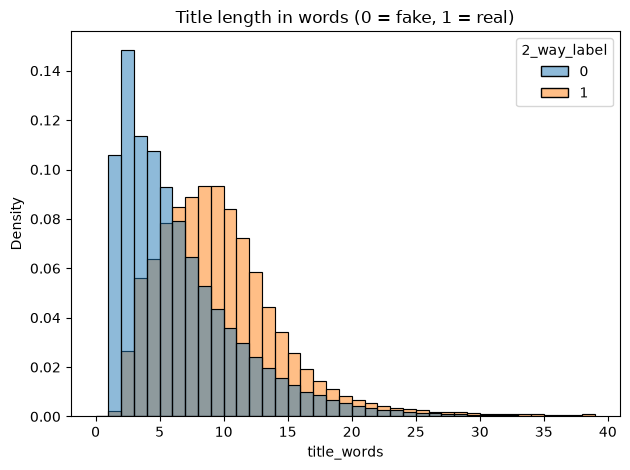

In [5]:
train_full["title_words"] = train_full["clean_title"].str.split().str.len()  # kiek zodziu antrasteje
print(train_full.groupby("2_way_label")["title_words"].describe().round(1))  # netikros antrastes trumpesnes: daznai tai tiesiog trumpas paveikslelio aprasas
sns.histplot(data=train_full, x="title_words", hue="2_way_label", bins=range(0, 40), stat="density", common_norm=False)  # abi grupes rodom procentais, nes netikru yra daugiau ir kitaip jos uzgoztu tikras
plt.title("Title length in words (0 = fake, 1 = real)"); plt.tight_layout(); plt.savefig(FIG / "title_length.png", dpi=120); plt.show()

In [6]:
sub = train_full.groupby("subreddit")["2_way_label"].agg(posts="size", share_real="mean").sort_values("posts", ascending=False)  # kiek irasu kiekviename subreddit ir kokia dalis tikru
sub

,posts,share_real
subreddit,,
psbattle_artwork,167857,0.0
mildlyinteresting,86237,1.0
photoshopbattles,55198,1.0
pareidolia,47331,0.0
fakehistoryporn,35576,0.0
nottheonion,31977,1.0
upliftingnews,23960,1.0
fakealbumcovers,21725,0.0
misleadingthumbnails,15962,0.0


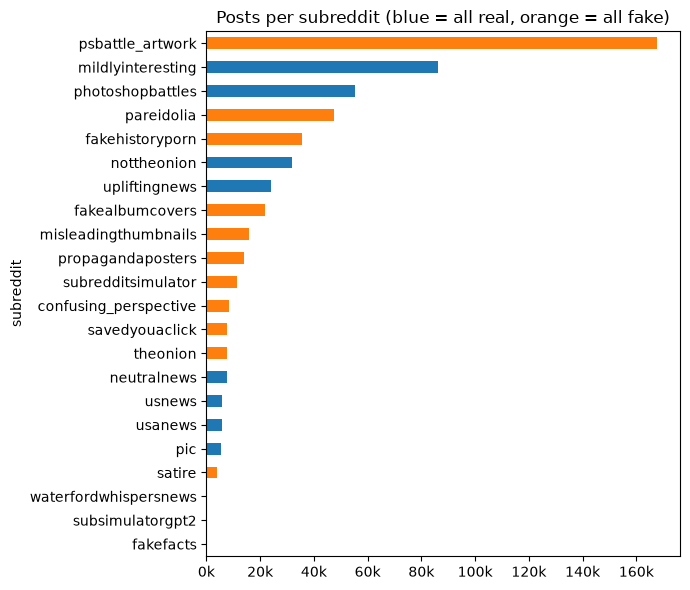

In [7]:
ax = sub["posts"].plot.barh(figsize=(7, 6), color=np.where(sub["share_real"] == 1, "tab:blue", "tab:orange"))  # spalva parodo, kad visas subreddit yra arba tik tikras, arba tik netikras
ax.invert_yaxis(); ax.xaxis.set_major_formatter(lambda x, _: f"{x / 1000:.0f}k"); ax.set_title("Posts per subreddit (blue = all real, orange = all fake)")  # skaicius rodom kaip 20k, kad nesusilietu
plt.tight_layout(); plt.savefig(FIG / "subreddits.png", dpi=120); plt.show()

Every subreddit is 100% fake or 100% real, because Fakeddit labels posts by the subreddit they come from. Using `subreddit` as a feature would leak the label, so it is dropped.

In [8]:
miss = train_full["num_comments"].isna()  # kur truksta komentaru skaiciaus
print("Rows with missing num_comments/upvote_ratio:", miss.sum())
print(train_full.loc[miss, "subreddit"].value_counts())  # visi tusti is vieno netikro subreddit, tai pati tustuma jau isduoda atsakyma

Rows with missing num_comments/upvote_ratio: 167857
subreddit
psbattle_artwork    167857
Name: count, dtype: int64


The missing engagement values all come from one fake subreddit (`psbattle_artwork`). They are filled with the median, but this is a known weak spot: missingness is itself correlated with the label.

## 3. Features
* All rows: 564,000 for training and 59,319 for testing (the official splits).
* Dropped: `subreddit` (label leak), `author`, `id`, `image_url` (identifiers, not content).
* `clean_title` -> TF-IDF (unigrams + bigrams).
* `score`, `num_comments`, `upvote_ratio` -> median imputation, clip negatives to 0, `log1p`, standard scaling.

In [9]:
FEATURES = ["clean_title", "score", "num_comments", "upvote_ratio"]  # subreddit neimam, nes jis tiesiog pasako atsakyma ir modelis nieko neismoktu
X_train, y_train = train_full[FEATURES], train_full["2_way_label"]  # visi 564k irasu: modelis su jais susitvarko per pusmineti, o daugiau pavyzdziu = geresni rezultatai
X_test, y_test = test_full[FEATURES], test_full["2_way_label"]  # visas oficialus testas, 59k irasu
print("min score:", X_train["score"].min())  # yra neigiamu tasku, o logaritmas su jais neveikia

min score: -950


In [10]:
numeric = make_pipeline(SimpleImputer(strategy="median"),  # tuscius langelius uzpildom viduriniu skaiciumi
                        FunctionTransformer(np.clip, kw_args={"a_min": 0, "a_max": None}, feature_names_out="one-to-one"),  # neigiamus taskus paverciam 0
                        FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler())  # logaritmas sumazina milziniskus skaicius (iki 137k), tada viska suvienodinam
features = ColumnTransformer([
    ("title", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50_000, sublinear_tf=True, stop_words="english"), "clean_title"),  # zodziai ir zodziu poros; ismetam zodzius, kurie pasitaiko tik karta
    ("meta", numeric, ["score", "num_comments", "upvote_ratio"]),
])
model = Pipeline([("features", features), ("clf", LogisticRegression(class_weight="balanced", max_iter=1000))])  # balanced: klaidos su retesne grupe (tikros) kainuoja daugiau, kad modelis ju neignoruotu

## 4. Train

In [11]:
model.fit(X_train, y_train)  # modelis mokosi tik is mokymo duomenu
print("TF-IDF vocabulary size:", len(model.named_steps["features"].named_transformers_["title"].vocabulary_))  # kiek skirtingu zodziu modelis zino

TF-IDF vocabulary size: 50000


## 5. Evaluate

In [12]:
pred = model.predict(X_test)  # modelio spejimai testui
print("Majority-class baseline accuracy:", round((y_test == 0).mean(), 4))  # palyginimui: kiek gautum visada spedamas 'netikra'
print("Model accuracy:", round(accuracy_score(y_test, pred), 4))
print(classification_report(y_test, pred, target_names=["fake", "real"], digits=4))  # precision: kiek spejimu buvo teisingi; recall: kiek is visu tikru atveju modelis rado

Majority-class baseline accuracy: 0.6037
Model accuracy: 0.8487
              precision    recall  f1-score   support

        fake     0.8980    0.8454    0.8709     35812
        real     0.7837    0.8537    0.8172     23507

    accuracy                         0.8487     59319
   macro avg     0.8409    0.8496    0.8441     59319
weighted avg     0.8527    0.8487    0.8496     59319



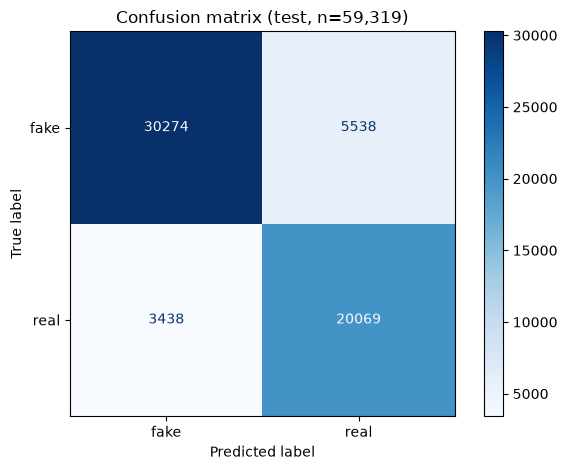

In [13]:
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["fake", "real"]).plot(cmap="Blues", values_format="d")  # lentele: kur modelis pataike ir kur suklydo
plt.title("Confusion matrix (test, n=59,319)"); plt.tight_layout(); plt.savefig(FIG / "confusion_matrix.png", dpi=120); plt.show()

## 6. Most informative words
Positive coefficients push towards **real**, negative towards **fake**.

In [14]:
names = model.named_steps["features"].get_feature_names_out()
coef = pd.Series(model.named_steps["clf"].coef_[0], index=names)  # kiekvieno zodzio taskai: + reiskia tikra, - reiskia netikra
print("Metadata coefficients:"); print(coef[coef.index.str.startswith("meta__")].round(3))  # kiek svarbus komentarai, taskai ir upvote santykis
words = coef[coef.index.str.startswith("title__")].rename(lambda s: s.removeprefix("title__"))  # paliekam tik zodzius
top = pd.DataFrame({"fake": words.nsmallest(15).index, "fake_coef": words.nsmallest(15).values.round(2),  # 15 labiausiai netikru ir 15 labiausiai tikru zodziu
                    "real": words.nlargest(15).index, "real_coef": words.nlargest(15).values.round(2)})
top

Metadata coefficients:
meta__score          -0.269
meta__num_comments    0.813
meta__upvote_ratio   -0.642
dtype: float64


,fake,fake_coef,real,real_coef
0,mrw,-10.62,donates,6.89
1,circa,-9.91,restaurant,6.01
2,til,-9.62,homeless,5.99
3,florida man,-7.46,police,5.96
4,colourized,-6.14,sign,5.83
5,hmb,-6.12,says,5.81
6,poster,-5.85,saves,5.70
7,colorised,-5.14,rescued,5.61
8,communism,-4.69,yearold,5.60
9,date unknown,-4.52,veterans,5.54


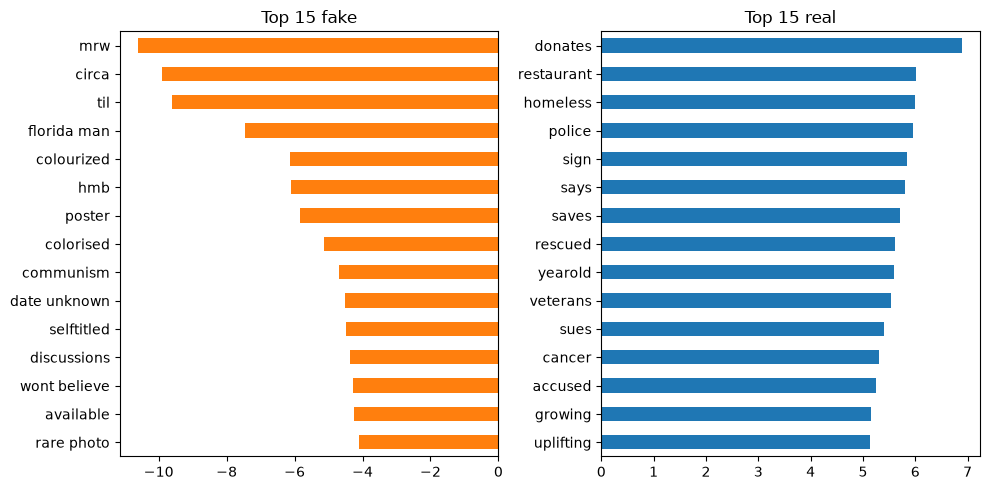

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
words.nsmallest(15).sort_values(ascending=False).plot.barh(ax=axes[0], color="tab:orange", title="Top 15 fake")
words.nlargest(15).sort_values().plot.barh(ax=axes[1], color="tab:blue", title="Top 15 real")
plt.tight_layout(); plt.savefig(FIG / "top_words.png", dpi=120); plt.show()

## 7. Save the pipeline
Load with `joblib.load("models/logreg_tfidf.joblib")` and call `.predict()` on a DataFrame with the four feature columns.

In [16]:
Path("../models").mkdir(exist_ok=True)
joblib.dump(model, "../models/logreg_tfidf.joblib")  # saugom visa grandine, kad veliau nereiktu is naujo ruosti duomenu
assert (joblib.load("../models/logreg_tfidf.joblib").predict(X_test) == pred).all()  # patikra: is failo ikeltas modelis speja taip pat